# A City Park, One Tree at a Time.

A different perspective on Vienna’s Stadtpark, one of the city’s most iconic green spaces. Each circle represents an individual tree, with its size reflecting the diameter of its canopy. Together, these hundreds of green dots reveal the park’s spatial structure, from dense clusters of vegetation to open spaces and winding pathways. A minimalist exploration of urban nature, showing how simple geospatial data can uncover the hidden patterns of a familiar landscape.

#30DayMapChallenge #Day1 #Points #Vienna #Stadtpark #GIS #GeoData #UrbanGreen

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

MAP_PATH = Path.cwd() / "maps"
MAP_PATH.mkdir(exist_ok=True, parents=True)

In [2]:
wfs_url = (
    "https://data.wien.gv.at/daten/geo?"
    "service=WFS&"
    "version=2.0.0&"
    "request=GetFeature&"
    "typeNames=ogdwien:BAUMKATOGD&"
    "bbox=16.378,48.203,16.385,48.206,EPSG:4326&"
    "srsName=EPSG:31256"
)

gdf = gpd.read_file(wfs_url)

<Axes: xlabel='x', ylabel='y'>

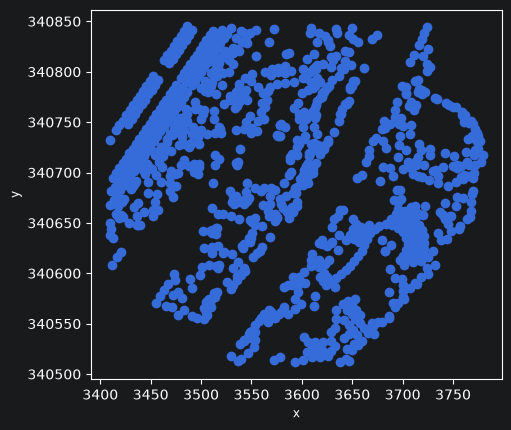

In [3]:
gdf.plot()

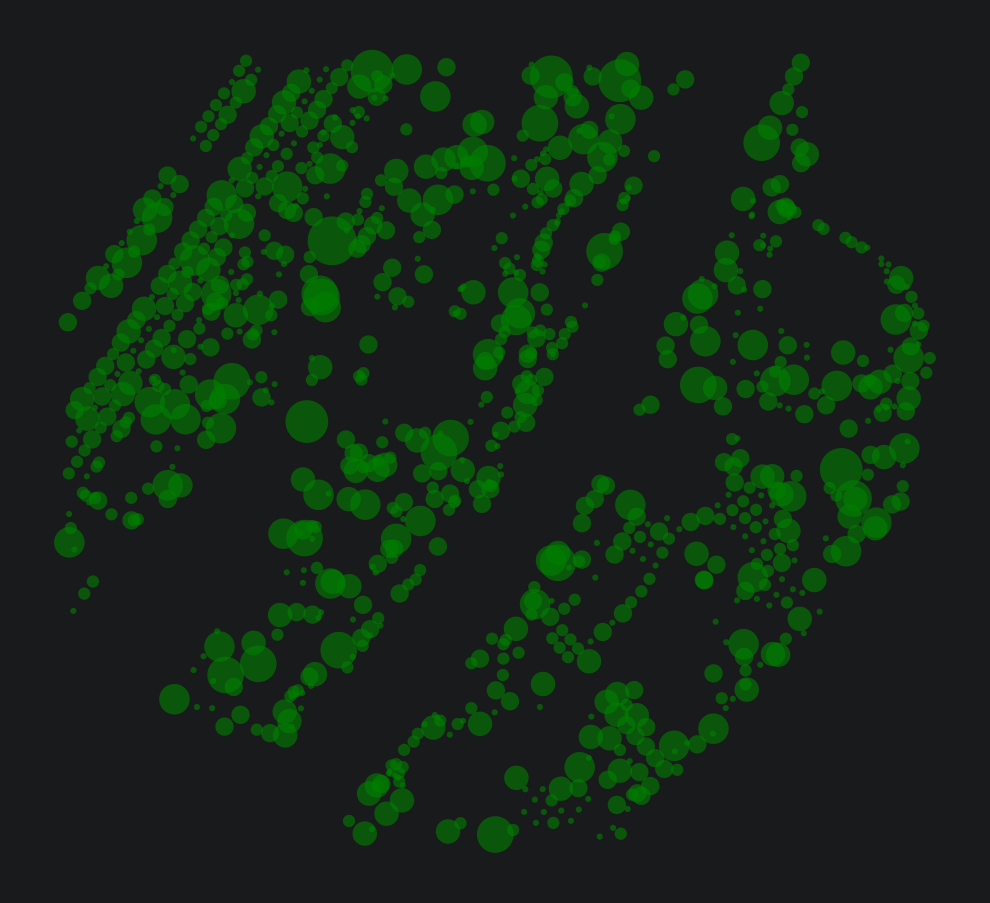

In [5]:
gdf["diameter"] = gdf["KRONENDURCHMESSER"].clip(0, 8) / 8 * 21
trees = gdf.copy()
trees["geometry"] = gdf.geometry.buffer(gdf["diameter"] / 2)

fig, ax = plt.subplots(figsize=(10, 10))

trees.plot(
    ax=ax,
    color="green",
    alpha=0.6,
    edgecolor="none"
)

ax.set_axis_off()
ax.set_aspect("equal")
plt.tight_layout()

plt.savefig(Path(MAP_PATH, "map01.png"), dpi=300, facecolor="white", bbox_inches="tight")

plt.show()